# Solidification beyond Scheil: diffusion in the solid with janus-kinetics

pycalphad, with its companion `scheil` package, gives the two classic limits of solidification: the lever
rule (full equilibrium) and the Scheil-Gulliver path (no diffusion in the solid). Real castings lie
between them, depending on how fast the solid can diffuse while it forms.
[janus-kinetics](https://github.com/odinzen/janus-kinetics)
([doi:10.5281/zenodo.23381870](https://doi.org/10.5281/zenodo.23381870)) is built to work with
pycalphad: it takes the thermodynamics from a pycalphad `Database` and adds the kinetics.

This example follows a Ni-18Al-2Cr (at.%) alloy, whose last liquid forms γ′ on the Scheil path, and shows
how much γ′ survives when the solid diffuses as it grows. The thermodynamics are the Al-Cr-Ni description
of Dupin, Ansara and Sundman (Calphad 25 (2001) 279) in `alcrni.tdb`, the same file as pycalphad's test
database. The diffusion uses the Ni-base mobilities of Campbell, Boettinger and Kattner (Acta Mater. 50
(2002) 775), which ship with janus-kinetics.

Install with `pip install git+https://github.com/odinzen/janus-kinetics`.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
from pycalphad import Database, equilibrium, variables as v

from janus_kinetics import SolutionPhase, TemperatureSchedule
from janus_kinetics import campbell2002_fcc_ni
from janus_kinetics.dendrite_tip import liquidus
from janus_kinetics.solidification import (
    equilibrium_start,
    scheil_gulliver,
    solve_solidification_to_end,
)

# quiet pycalphad's TYPE_DEFINITION notes and the magnetic-model reminder
warnings.filterwarnings("ignore")

db = Database("alcrni.tdb")
comps = ["AL", "CR", "NI"]  # Ni last: it is the dependent element
alloy = [0.18, 0.02]  # mole fractions of Al and Cr

## The liquidus and the equilibrium (lever-rule) path

janus-kinetics wraps the phases it needs from the same database: the primary γ (FCC_A1), with its
mobilities, and the liquid. The liquidus comes from equal chemical potentials of every element in the two
phases; the equilibrium path is plain pycalphad.

In [2]:
mobility = campbell2002_fcc_ni()
gamma = SolutionPhase(db, "FCC_A1", comps, mobility_db=mobility)
melt = SolutionPhase(db, "LIQUID", comps, mobilities=False)
t_liquidus = liquidus(gamma, melt, alloy, 1680.0).temperature
print(f"liquidus {t_liquidus:.1f} K")

temps = np.arange(np.floor(t_liquidus), 1560.0, -1.0)
conditions = {v.T: temps, v.P: 101325, v.N: 1,
              v.X("AL"): alloy[0], v.X("CR"): alloy[1]}
eq = equilibrium(db, comps + ["VA"], ["LIQUID", "L12_FCC"], conditions)
phase = np.squeeze(eq.Phase.values)
amount = np.squeeze(eq.NP.values)
liquid_amount = np.where(phase == "LIQUID", amount, 0.0)
lever = 1 - np.nansum(liquid_amount, axis=-1)

liquidus 1681.4 K


## The Scheil-Gulliver path, with γ and γ′ told apart

In this database γ and γ′ are one L1<sub>2</sub> model, and pycalphad names both `L12_FCC`. The
`disordered` argument labels composition sets whose sublattices hold the same fractions as `FCC_A1` (γ),
so only ordered γ′ keeps the name `L12_FCC`.

In [3]:
ordered = {"L12_FCC": "FCC_A1"}
scheil = scheil_gulliver(db, comps, ["LIQUID", "L12_FCC"], alloy,
                         t_liquidus + 1, 1.0, stop_fraction=1e-3,
                         t_min=1500.0, disordered=ordered)

# the first temperature at which ordered gamma' forms
first = next(T for T, step in zip(scheil.temperatures[1:], scheil.solids)
             if any(name == "L12_FCC" for name, _, _ in step))
gp_scheil = scheil.solid_phase_fractions()["L12_FCC"]
print(f"gamma' first forms at {first:.1f} K")
print(f"Scheil gamma' fraction {gp_scheil:.4f}")

gamma' first forms at 1615.4 K
Scheil gamma' fraction 0.0638


## Back-diffusion: the solid diffuses as it grows

`solve_solidification_to_end` grows the primary γ from the centre of a volume element, half a secondary
dendrite arm spacing wide (25 µm here), with local equilibrium at the solid/liquid interface and a
uniform liquid, while the temperature falls at a constant rate. Every degree it checks whether the liquid
would form another solid; once γ′ appears, solid diffusion is dropped and the rest of the liquid follows
the Scheil path, as Kattner, Boettinger and Coriell (Z. Metallkd. 87 (1996) 522) treat the eutectic. For
speed the solid's interdiffusion matrix is taken once, from Campbell's mobilities near the solidus
(1650 K).

In [4]:
d_solid = gamma.interdiffusion_matrix([0.16, 0.018], 1650.0)
print("interdiffusion matrix of gamma at 1650 K (m^2/s):")
print(d_solid)
start = equilibrium_start(db, comps, "FCC_A1", "LIQUID", alloy,
                          t_liquidus - 0.5)


def solidify(rate, span=120.0):
    """Back-diffusion at `rate` K/s, handed to Scheil once gamma' forms."""
    t0, t_end = t_liquidus - 0.5, span / rate
    cooling = TemperatureSchedule([0.0, t_end], [t0, t0 - span])
    return solve_solidification_to_end(
        db, ["LIQUID", "L12_FCC"], gamma, melt, cooling, t_end,
        25e-6, start, step=1.0, solid_diffusivity=d_solid, cells=40,
        dt=0.2 / rate, disordered=ordered)


runs = {rate: solidify(rate) for rate in (1000.0, 100.0, 30.0, 10.0)}

interdiffusion matrix of gamma at 1650 K (m^2/s):
[[2.87696066e-12 1.59494653e-12]
 [2.03264156e-13 6.44814141e-13]]


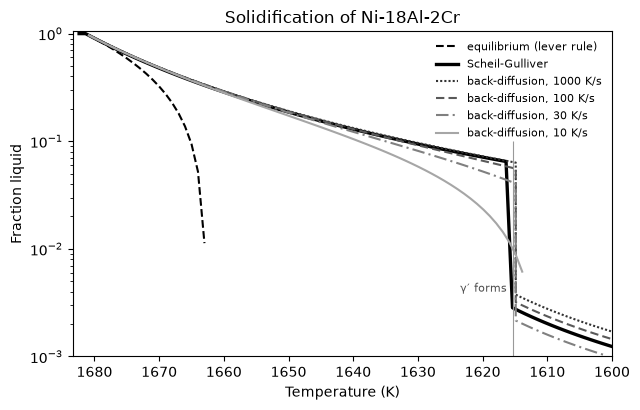

In [5]:
# the paths part in the last few percent of liquid, hence the log scale
floor = 1e-3


def liquid(fraction_solid):
    f = 1 - np.asarray(fraction_solid)
    return np.where(f > floor, f, np.nan)  # no line once the liquid is gone


styles = {1000.0: (0, (1, 1)), 100.0: (0, (4, 2)),
          30.0: (0, (6, 2, 1, 2)), 10.0: "-"}
greys = {1000.0: "0.2", 100.0: "0.35", 30.0: "0.5", 10.0: "0.65"}

fig, ax = plt.subplots(figsize=(6.5, 4.2))
ax.semilogy(temps, liquid(lever), "k--", label="equilibrium (lever rule)")
ax.semilogy(scheil.temperatures, liquid(scheil.fraction_solid), "k-",
            lw=2.4, label="Scheil-Gulliver")
for rate, run in runs.items():
    ax.semilogy(run.temperatures, liquid(run.fraction_solid),
                linestyle=styles[rate], color=greys[rate],
                label=f"back-diffusion, {rate:g} K/s")
ax.vlines(first, floor, 0.1, color="0.6", lw=0.8)
ax.annotate("γ′ forms", (first, 0.004), xytext=(-4, 0),
            textcoords="offset points", fontsize=8, color="0.3", ha="right")
ax.set_xlim(1600, t_liquidus + 2)
ax.set_ylim(floor, 1.05)
ax.invert_xaxis()
ax.set_xlabel("Temperature (K)")
ax.set_ylabel("Fraction liquid")
ax.set_title("Solidification of Ni-18Al-2Cr")
ax.legend(frameon=False, fontsize=8, loc="upper right")
fig.tight_layout()

In [6]:
rows = [("Scheil-Gulliver", gp_scheil)]
for rate, run in runs.items():
    gp = run.phase_fractions().get("L12_FCC", 0.0)
    rows.append((f"back-diffusion, {rate:g} K/s", gp))
rows += [("equilibrium", 0.0)]

print(f"{'path':<28}{'gamma prime':>12}")
for name, fraction in rows:
    print(f"{name:<28}{fraction:>12.4f}")

path                         gamma prime
Scheil-Gulliver                   0.0638
back-diffusion, 1000 K/s          0.0623
back-diffusion, 100 K/s           0.0548
back-diffusion, 30 K/s            0.0400
back-diffusion, 10 K/s            0.0000
equilibrium                       0.0000


Diffusion in the solid lets the primary γ take up Al that the Scheil path leaves in the liquid, so the
last liquid is less enriched and less γ′ forms: from the Scheil value at fast cooling down to none at
10 K/s, where the solid keeps up and freezing ends as γ alone, as on the equilibrium path.

Assumptions worth knowing: a plate-like volume element (cylinders and spheres are options), a fixed
interdiffusion matrix, a uniform liquid, and no undercooling at the dendrite tip (janus-kinetics also has
a tip model). The back-diffusion solver stops when its liquid layer falls below about 2 % of its starting
thickness and no longer converges; the remaining liquid then counts as liquid in the totals, which the
10 K/s run reaches with well under 1 % left.

The models, their sources and how each is checked against its paper are in the
[janus-kinetics documentation](https://github.com/odinzen/janus-kinetics/blob/main/docs/validation.md).